# Oil products demand — 02 Research & results: US jet fuel

**Question.** Can a gradient-boosted tree, fed lagged demand and a physical indicator readable the next day, the kerosene burned by the commercial jets leaving US airports, forecast monthly US jet fuel demand up to twelve months ahead better than a seasonal naive?

**State of this run.** OpenSky's Trino access was not granted when this notebook was run, so the burn index does not exist yet. The model below runs on lagged demand only. That is not wasted work: it is the exact bar the index will have to clear, horizon by horizon, and section 7 is written to show the comparison as soon as `python -m src.download opensky` has filled the data.

This notebook reads the point-in-time dataset built in `01_data_jet.ipynb` and the walk-forward backtests written by `python -m src.model`. It performs no data operation of its own.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as c, data, model, sql

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 250)
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.grid": True, "grid.alpha": .3})

LABEL = {"xgboost": "xgboost", "naive": "seasonal naive", "last": "last value"}
STYLE = {"xgboost": dict(color="C1"), "naive": dict(color="C0", ls="--"), "last": dict(color="0.5", ls=":")}

In [2]:
df, lag = data.dataset("jet"), c.DEMAND_LAG["jet"]           # the panel of notebook 01
bt = sql.query("SELECT * FROM backtest WHERE product = 'jet'")  # one row per origin and horizon
marked = model.scored(bt)                                     # target published, no 2020 in origin, target or reference
print(f"drivers in the dataset: {list(df.columns.drop('demand')) or 'none yet'}")

drivers in the dataset: none yet


## 1. Key findings

In [3]:
# WAPE in %, averaged over the twelve horizons: the model against its two free benchmarks
headline = model.wape(bt).rename(LABEL).to_frame("WAPE, %").T
headline["gain on seasonal naive, %"] = 100 * (1 - headline["xgboost"] / headline["seasonal naive"])
headline["gain on last value, %"] = 100 * (1 - headline["xgboost"] / headline["last value"])
print(f"walk-forward backtest, {marked['origin'].nunique()} monthly origins {marked['origin'].min():%b %Y} to {marked['origin'].max():%b %Y}")
headline

walk-forward backtest, 125 monthly origins Jan 2015 to Jul 2026


,xgboost,seasonal naive,last value,"gain on seasonal naive, %","gain on last value, %"
"WAPE, %",4.28,4.99,5.67,14.15,24.49


FINDINGS

## 2. The forecasting problem

- **Target.** Monthly US kerosene-type jet fuel product supplied, EIA Petroleum Supply Monthly, kb/d.
- **Origin.** The last day of month *t*. The information set is everything published by then: demand up to *t − 2* (the Petroleum Supply Monthly comes out at the end of the second month after), and, once it exists, the burn index up to the day before.
- **Horizon.** Months *t+1* to *t+12*, forecast directly: one model per step, each trained on its own target, never a forecast fed back as an input.
- **Benchmarks.** *Seasonal naive*: the same calendar month in the latest year already published at the origin. *Last value*: the newest published print, held flat. Both are free and use the same information set.
- **Model.** `XGBRegressor` on the log deviation from the seasonal naive, `y = log demand(t+step) − log naive`. The forecast is the naive times `exp(prediction)`. If the model learns nothing it predicts zero and returns the naive.
- **Evaluation.** Expanding-window walk-forward: at every month end since January 2015 the twelve models are refitted on what was published by then, and the forecasts are marked later against the published outcome. WAPE (sum of absolute errors over sum of actuals) is the headline; MAE and RMSE in kb/d; bias.
- **2020 is left out** of training and of the headline (`config.EXCLUDE`). The backtest still forecasts through it; section 6 shows those forecasts apart.

In [4]:
# one past origin, used for the walk-through below: everything published by 31 December 2023
origin = pd.Timestamp("2023-12-01")
months = pd.date_range(origin + pd.DateOffset(months=1), periods=model.HORIZON, freq="MS", name="target month")
reference = [m - pd.DateOffset(months=model.back(step, lag)) for step, m in enumerate(months, 1)]
print(f"newest demand print at the origin: {origin - pd.DateOffset(months=lag):%B %Y}")
pd.DataFrame({"step": range(1, model.HORIZON + 1), "seasonal naive repeats": reference}, index=months).T

newest demand print at the origin: October 2023


target month,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01
step,1,2,3,4,5,6,7,8,9,10,11,12
seasonal naive repeats,2023-01-01 00:00:00,2023-02-01 00:00:00,2023-03-01 00:00:00,2023-04-01 00:00:00,2023-05-01 00:00:00,2023-06-01 00:00:00,2023-07-01 00:00:00,2023-08-01 00:00:00,2023-09-01 00:00:00,2023-10-01 00:00:00,2022-11-01 00:00:00,2022-12-01 00:00:00


Steps 11 and 12 reach back two years: at the end of December 2023 the figures for November and December 2023 are not out yet. A naive that used them would be looking ahead.

## 3. Demand: level, seasonality, persistence

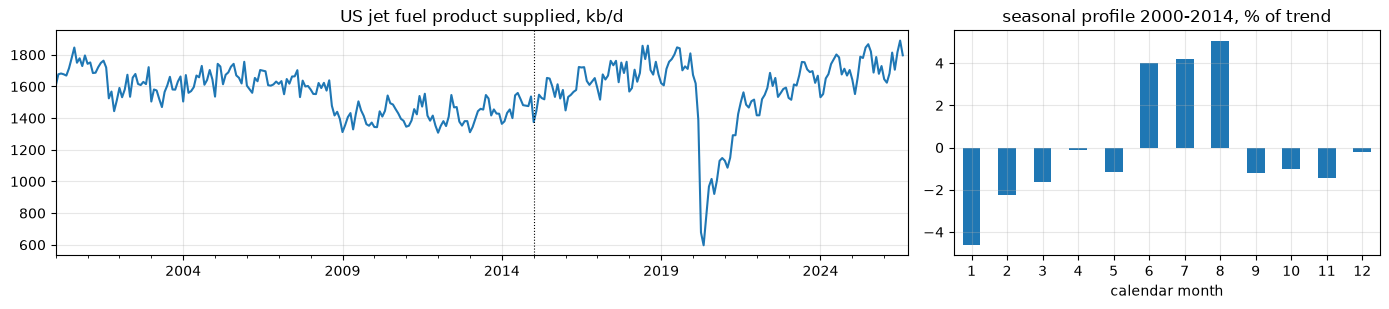

In [5]:
history = df.loc[df.index < c.BACKTEST_START, "demand"]  # only what precedes the backtest informs the design

# seasonal profile: each month against its centred twelve-month average, in %
profile = 100 * (history / history.rolling(12, center=True).mean() - 1)
profile = profile.groupby(profile.index.month).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.2), width_ratios=[2, 1])
df.loc[c.SAMPLE_START:, "demand"].plot(ax=axes[0], title="US jet fuel product supplied, kb/d")
axes[0].axvline(pd.Timestamp(c.BACKTEST_START), color="k", lw=.8, ls=":"); axes[0].set_xlabel("")
profile.plot.bar(ax=axes[1], rot=0, title="seasonal profile 2000-2014, % of trend"); axes[1].set_xlabel("calendar month")
plt.tight_layout();

In [6]:
# persistence before the backtest: autocorrelation of the level and of the year-on-year log change
yoy = np.log(history).diff(12)
pd.Series({"level, 1 month": history.autocorr(1), "level, 12 months": history.autocorr(12),
           "year-on-year, 1 month": yoy.autocorr(1), "year-on-year, 12 months": yoy.autocorr(12),
           "seasonal swing, % of trend": profile.max() - profile.min()}).to_frame("jet").T

,"level, 1 month","level, 12 months","year-on-year, 1 month","year-on-year, 12 months","seasonal swing, % of trend"
jet,0.85,0.74,0.63,-0.23,9.69


In [7]:
# has demand come back? Each year against 2019, the last year before the pandemic, %
yearly = df["demand"].dropna().resample("YE").mean()
yearly.index = yearly.index.year
(100 * (yearly.loc[2015:] / yearly.loc[2019] - 1)).to_frame("% of 2019").T

month,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% of 2019,-11.18,-7.36,-3.52,-2.05,0.00,-38.16,-21.47,-10.53,-5.16,-3.03,-0.35,0.27


SEASONS

## 4. Features

Everything enters in year-on-year terms, so the model sees growth rather than levels: the last twelve published demand prints (`yoy_lag`) and, once it exists, the 28-day mean of the burn index as readable at the origin against its value a year earlier.

In [8]:
X, y = model.features(df, lag, step=12)
X.loc[origin].to_frame(f"origin {origin:%b %Y}").T  # one row: the information set at the origin

,yoy_lag2,yoy_lag3,yoy_lag4,yoy_lag5,yoy_lag6,yoy_lag7,yoy_lag8,yoy_lag9,yoy_lag10,yoy_lag11,yoy_lag12,yoy_lag13
origin Dec 2023,0.09,0.10,0.03,0.09,0.04,0.05,0.04,0.06,0.07,0.07,0.05,0.05


In [9]:
# the target at this origin by hand: log of December 2024 over December 2022, the naive's reference
target = origin + pd.DateOffset(months=12)
by_hand = np.log(df.loc[target, "demand"] / df.loc[target - pd.DateOffset(months=model.back(12, lag)), "demand"])
assert abs(by_hand - y.loc[origin]) < 1e-12
by_hand

np.float64(0.06735939747921257)

## 5. Training and tuning without look-ahead

**Training rows.** A row can be used at an origin only if its *target* had been published by then. For the twelve-month model that removes the last fourteen months before the origin, not twelve. Rows whose origin, target or naive reference falls in 2020 are left out of training: the model is not asked to learn a lockdown.

In [10]:
rows = model.trainable(y, step=12, product="jet", origin=origin)
last = X.index[rows].max()
assert last + pd.DateOffset(months=12 + lag) <= origin  # its target was published by the origin
pd.DataFrame({"training rows": [rows.sum()], "first origin": [X.index[rows].min()], "last origin": [last],
              "its target month": [last + pd.DateOffset(months=12)],
              "target published by the end of": [last + pd.DateOffset(months=12 + lag)]})

,training rows,first origin,last origin,its target month,target published by the end of
0,226,2001-01-01,2022-10-01,2023-10-01,2023-12-01


In [11]:
# one model per horizon, each with its own training rows; and at the first backtest origin, January 2015
first = pd.Timestamp(c.BACKTEST_START)
pd.DataFrame({when: {step: model.trainable(model.features(df, lag, step)[1], step, "jet", at).sum() for step in range(1, model.HORIZON + 1)}
              for when, at in (("origin Dec 2023", origin), ("first origin, Jan 2015", first))}).T

,1,2,3,4,5,6,7,8,9,10,11,12
origin Dec 2023,249,248,247,246,245,244,243,242,241,240,227,226
"first origin, Jan 2015",166,165,164,163,162,161,160,159,158,157,155,155


**Tuning.** Eight parameter sets, chosen once at the first backtest origin by expanding-window cross-validation on the data published by then. The backtest years play no part in the choice.

In [12]:
fit_rows = model.trainable(y, 12, "jet", first)
cv = pd.DataFrame(model.GRID)
cv["cv rmse, %"] = [100 * np.sqrt(model.cv_score(X[fit_rows], y[fit_rows], 12, lag, params)) for params in model.GRID]
cv.sort_values("cv rmse, %")

,learning_rate,max_depth,n_estimators,"cv rmse, %"
2,0.03,5,200,11.06
0,0.03,3,200,11.08
6,0.10,5,200,11.12
3,0.03,5,600,11.12
7,0.10,5,600,11.12
1,0.03,3,600,11.33
4,0.10,3,200,11.37
5,0.10,3,600,11.37


In [13]:
assert model.tuned("jet") == model.tune(df, "jet", first)  # what the backtest stored is the best line above
sql.query("SELECT * FROM params WHERE product = 'jet'")

,product,learning_rate,max_depth,n_estimators
0,jet,0.03,5,200


**The direct test for look-ahead.** Delete from the dataset everything that was not published at the origin, the demand prints of the last two months and every later row, and forecast again. If any step of the pipeline read the future, the forecast would change.

In [14]:
path = model.forecast(df, "jet", origin, model.tuned("jet"))
known = df.loc[:origin].copy()
known.loc[known.index > origin - pd.DateOffset(months=lag), "demand"] = np.nan  # not published yet at the origin
assert (model.forecast(known, "jet", origin, model.tuned("jet")) == path).all()
pd.DataFrame({"xgboost": path, "seasonal naive": model.seasonal_naive(df, lag, origin), "actual": df["demand"].reindex(path.index)}).T

,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01
xgboost,"1,588.35","1,592.00","1,670.53","1,702.15","1,755.97","1,841.79","1,817.65","1,818.29","1,767.79","1,768.94","1,713.67","1,727.94"
seasonal naive,"1,528.00","1,516.00","1,613.00","1,606.00","1,670.00","1,755.00","1,753.00","1,708.00","1,691.00","1,697.00","1,584.00","1,593.00"
actual,"1,532.00","1,552.00","1,651.00","1,678.00","1,742.00","1,772.00","1,802.00","1,784.00","1,676.00","1,712.00","1,669.00","1,704.00"


## 6. Walk-forward backtest

The same procedure from every month end since January 2015, stored by `python -m src.model`.

In [15]:
# integrity of the stored backtest: every target is after its origin, and every naive reference had been published by the origin
def months_between(start, end):
    return (end.dt.year - start.dt.year) * 12 + end.dt.month - start.dt.month

assert (months_between(bt["origin"], bt["month"]) == bt["step"]).all()
assert (months_between(bt["reference"], bt["origin"]) >= lag).all()
pd.Series({"origins": bt["origin"].nunique(), "first origin": bt["origin"].min(), "last origin": bt["origin"].max(),
           "forecasts": len(bt), "marked": bt["actual"].notna().sum(), "marked outside 2020": len(marked)}).to_frame("jet").T

,origins,first origin,last origin,forecasts,marked,marked outside 2020
jet,140,2015-01-01 00:00:00,2026-08-01 00:00:00,1680,1602,1291


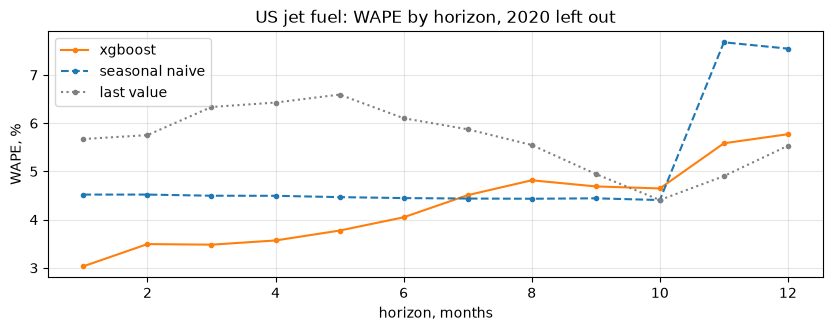

In [16]:
# error by horizon
by_step = model.score(marked)
ax = plt.gca()
for name in model.FORECASTS:
    by_step["wape"][name].plot(ax=ax, marker="o", ms=3, label=LABEL[name], **STYLE[name])
ax.set_title("US jet fuel: WAPE by horizon, 2020 left out"); ax.set_xlabel("horizon, months"); ax.set_ylabel("WAPE, %"); ax.legend();

In [17]:
# every metric by horizon. MAE and RMSE in kb/d, WAPE and bias in %
by_step.round(2)

mae                  rmse                  wape               bias            
     xgboost  naive   last xgboost  naive   last xgboost naive last xgboost naive  last
step                                                                                   
1      50.57  75.36  94.56   74.01  99.99 106.98    3.03  4.52 5.67   -1.27 -4.02 -0.98
2      58.31  75.45  96.02   90.60 100.24 118.30    3.49  4.52 5.75   -1.74 -4.02 -1.23
3      58.15  75.10 105.82   92.51 100.10 130.28    3.48  4.50 6.34   -1.97 -3.99 -1.53
4      59.65  75.12 107.44   93.17 100.32 133.52    3.57  4.49 6.43   -1.99 -3.98 -1.81
5      63.13  74.73 110.29   96.84 100.13 130.56    3.77  4.47 6.59   -2.34 -3.95 -2.09
6      67.74  74.41 102.10  101.32 100.04 120.06    4.05  4.45 6.10   -2.67 -3.93 -2.36
7      75.43  74.26  98.28  110.37 100.12 113.69    4.51  4.44 5.87   -2.96 -3.91 -2.68
8      80.62  74.21  92.87  114.48 100.29 110.59    4.82  4.43 5.55   -3.30 -3.90 -3.06
9      78.55  74.42  82.86  110.54 100.63 106.40    4.69  4.44 4.95   -3.25 -3.91 -3.52
10     77.88  73.85  73.85  107.99 100.25 100.25    4.65  4.41 4.41   -3.23 -3.87 -3.87
11     94.40 129.79  82.89  131.50 156.00 102.16    5.58  7.68 4.90   -4.17 -7.23 -3.41
12     97.76 127.80  93.71  134.93 153.93 114.07    5.77  7.55 5.53   -4.70 -7.46 -3.58

BACKTEST

In [18]:
# by target year, WAPE %. This table keeps 2020 and the months that reference it, which the headline leaves out
everything = model.scored(bt, shocks=True)
everything = everything.assign(year=everything["month"].dt.year)
by_year = model.score(everything, "year")["wape"].rename(columns=LABEL)
by_year

,xgboost,seasonal naive,last value
year,,,
2015,3.76,5.10,5.93
2016,3.64,4.98,5.78
2017,3.47,4.84,5.12
2018,2.29,3.70,5.51
2019,3.21,3.28,5.22
2020,62.98,62.34,54.89
2021,34.26,35.59,25.90
2022,16.71,16.15,8.69
2023,6.87,7.58,5.84


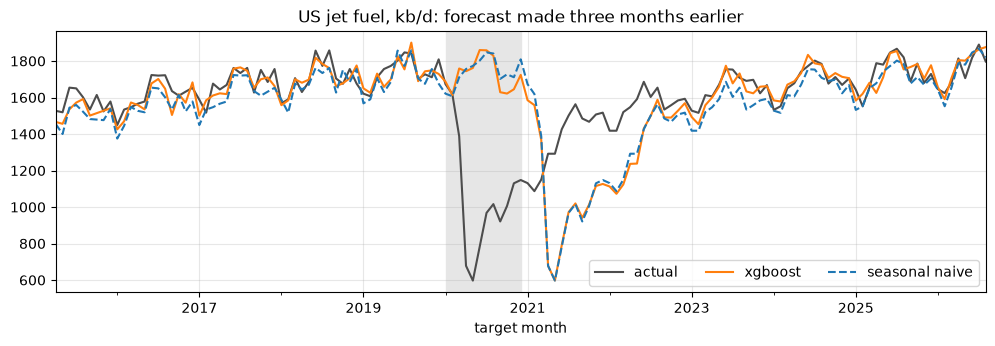

In [19]:
# actual against forecast, three months ahead, with 2020 shaded
three = everything[everything["step"] == 3].set_index("month")
ax = three["actual"].plot(color="0.3", label="actual", figsize=(12, 3.4))
three["xgboost"].plot(ax=ax, label="xgboost", **STYLE["xgboost"])
three["naive"].plot(ax=ax, label="seasonal naive", **STYLE["naive"])
ax.axvspan(pd.Timestamp(c.COVID[0]), pd.Timestamp(c.COVID[1]), color="0.9")
ax.set_title("US jet fuel, kb/d: forecast made three months earlier"); ax.set_xlabel("target month"); ax.legend(ncol=3);

origins where the model beat the naive: 70%


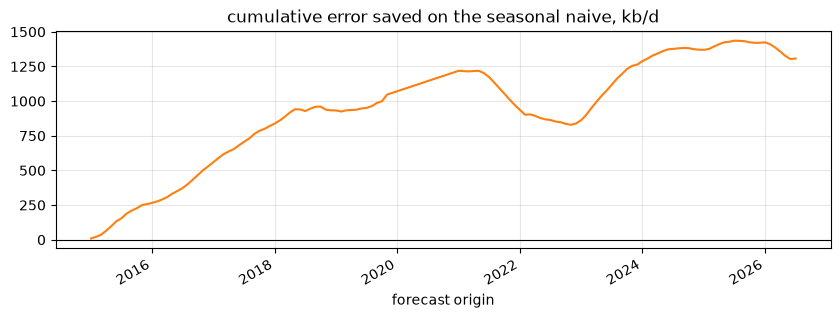

In [20]:
# where the model earns or loses against the naive: absolute error saved, cumulated over forecast origins
saved = ((marked["naive"] - marked["actual"]).abs() - (marked["xgboost"] - marked["actual"]).abs()).groupby(marked["origin"]).mean()
ax = saved.cumsum().plot(color="C1", title="cumulative error saved on the seasonal naive, kb/d")
ax.axhline(0, color="k", lw=.8); ax.set_xlabel("forecast origin")
print(f"origins where the model beat the naive: {(saved > 0).mean():.0%}")

YEARS

## 7. The burn index: does it help, and against what bar?

Two tests, both out-of-sample. **The gain by horizon**: the backtest rerun without the burn index, the same parameters, horizon by horizon, read against the seed band, the spread of the same model under three other random seeds. **The index against the EIA weekly figure**: the weekly Petroleum Status Report is the free nowcast the index competes with, out a week after the fact against a day.

In [21]:
ablation = sql.query("SELECT * FROM ablation WHERE product = 'jet'")
seeds = sql.query("SELECT * FROM seeds WHERE product = 'jet'")
runs = pd.concat([seeds, ablation[ablation["variant"] == "all drivers"].assign(seed=model.PARAMS["random_state"])])
band = runs.groupby("step")["xgboost"].agg(lambda s: s.max() - s.min()).rename("seed noise, WAPE points")
steps = ablation.pivot_table(index="step", columns="variant", values="xgboost")
if "lags only" in steps:
    gain = (steps["lags only"] - steps["all drivers"]).rename("burn index helps by, WAPE points")
    fig, ax = plt.subplots()
    ax.bar(gain.index, gain, color="C2", label="WAPE without the index minus with it")
    ax.fill_between(band.index, -band, band, color="0.85", zorder=0, label="seed noise, max - min")
    ax.axhline(0, color="k", lw=.7); ax.set_xlabel("horizon, months"); ax.legend()
    print(pd.concat([gain, band], axis=1).T.round(2))
else:
    print("No driver yet: the backtest above is the lags-only model. The burn index will count where its gain exceeds the seed noise:")
band.to_frame().T

No driver yet: the backtest above is the lags-only model. The burn index will count where its gain exceeds the seed noise:


step,1,2,3,4,5,6,7,8,9,10,11,12
"seed noise, WAPE points",0.04,0.12,0.03,0.09,0.17,0.19,0.26,0.10,0.06,0.09,0.10,0.21


In [22]:
# the bar set by the weekly figure: its monthly mean against the monthly demand EIA publishes two months later,
# in year-on-year growth, the terms the model sees
weekly = sql.query("SELECT period_end, value FROM predictors WHERE product = 'jet' AND variable = 'product_supplied_weekly'")
weekly = weekly.set_index(pd.to_datetime(weekly["period_end"]))["value"].resample("MS").mean()
monthly = df["demand"].dropna()
growth = pd.DataFrame({"monthly": np.log(monthly).diff(12), "weekly": np.log(weekly).diff(12)}).dropna()
growth = growth[~model.excluded(growth.index, "jet")]
burn = sql.query("SELECT period_end, value FROM predictors WHERE product = 'jet' AND variable = 'burn'")
if len(burn):
    burn = burn.set_index(pd.to_datetime(burn["period_end"]))["value"].resample("MS").mean()
    growth["burn"] = np.log(burn).diff(12)
    pd.DataFrame({"burn, kb/d": burn, "EIA monthly, kb/d": monthly}).dropna().plot(title="burn index against EIA, kb/d")
growth = growth.dropna()
pd.DataFrame({name: {"correlation with monthly": growth[name].corr(growth["monthly"]),
                     "mean absolute gap, points": 100 * (growth[name] - growth["monthly"]).abs().mean(),
                     "months": len(growth)} for name in growth.columns.drop("monthly")}).T

,correlation with monthly,"mean absolute gap, points",months
weekly,0.92,3.34,296.00


INDEX

## 8. Current forecast

The same models fitted at the latest origin, with the parameters the backtest chose.

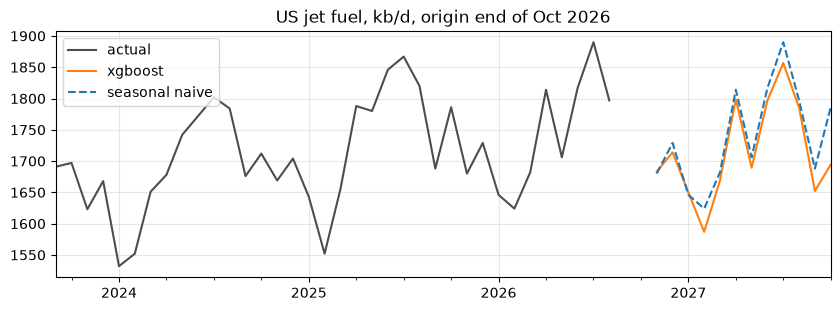

In [23]:
last_origin = df.index[-1]
latest = pd.DataFrame({"xgboost": model.forecast(df, "jet", last_origin, model.tuned("jet")),
                       "naive": model.seasonal_naive(df, lag, last_origin)})
ax = df["demand"].dropna().iloc[-36:].plot(color="0.3", label="actual")
latest["xgboost"].plot(ax=ax, label="xgboost", **STYLE["xgboost"])
latest["naive"].plot(ax=ax, label="seasonal naive", **STYLE["naive"])
ax.set_title(f"US jet fuel, kb/d, origin end of {last_origin:%b %Y}"); ax.set_xlabel(""); ax.legend();

In [24]:
# the forecast as a deviation from the seasonal naive, in %
(100 * (latest["xgboost"] / latest["naive"] - 1)).to_frame("xgboost over naive, %").T

,2026-11-01,2026-12-01,2027-01-01,2027-02-01,2027-03-01,2027-04-01,2027-05-01,2027-06-01,2027-07-01,2027-08-01,2027-09-01,2027-10-01
"xgboost over naive, %",0.19,-0.87,0.24,-2.28,-0.76,-0.84,-0.97,-1.09,-1.76,-0.65,-2.12,-5.14


CURRENT

## 9. Limitations

LIMITS

## 10. Conclusion

CONCLUSION